In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [4]:


df = pd.read_csv('winedata.csv')

In [5]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [9]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

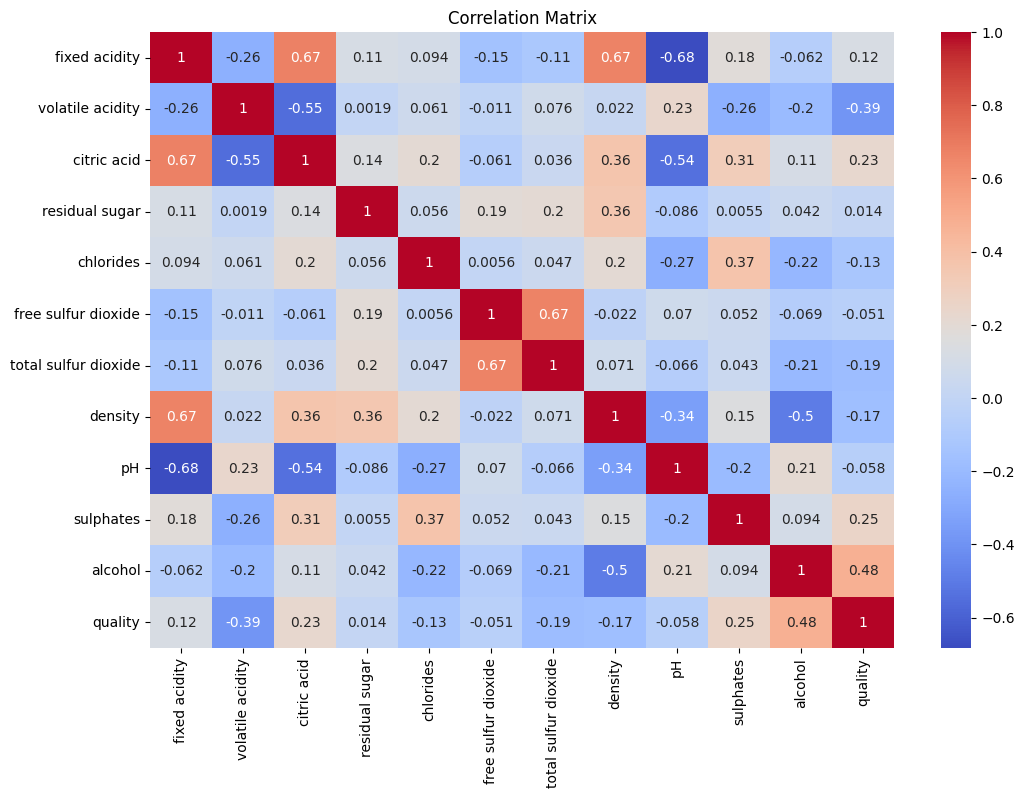

In [10]:
corr = df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [11]:
corr['quality'].sort_values(ascending=False)

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

In [12]:
df['quality_label'] = np.where(df['quality'] >= 7, 1, 0)

df[['quality','quality_label']].head()


,quality,quality_label
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0


In [14]:
X = df.drop(['quality', 'quality_label'], axis=1)

y = df['quality_label']

In [15]:
X

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2


In [16]:
y

0       0
1       0
2       0
3       0
4       0
       ..
1594    0
1595    0
1596    0
1597    0
1598    0
Name: quality_label, Length: 1599, dtype: int32

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:
#logistic regression without scaling
lr = LogisticRegression(max_iter=5000)

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

In [19]:
print("Accuracy:", accuracy_score(y_test,y_pred))
print("Precision:", precision_score(y_test,y_pred))
print("Recall:", recall_score(y_test,y_pred))
print("F1 Score:", f1_score(y_test,y_pred))

Accuracy: 0.859375
Precision: 0.55
Recall: 0.23404255319148937
F1 Score: 0.3283582089552239


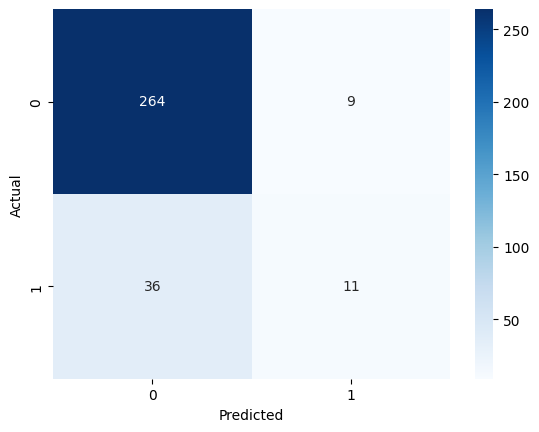

In [20]:
cm = confusion_matrix(y_test,y_pred)

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [21]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92       273
           1       0.55      0.23      0.33        47

    accuracy                           0.86       320
   macro avg       0.72      0.60      0.62       320
weighted avg       0.83      0.86      0.83       320



In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [23]:
lr_scaled = LogisticRegression(max_iter=5000)

lr_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [24]:
print("Accuracy:", accuracy_score(y_test,y_pred_scaled))
print("Precision:", precision_score(y_test,y_pred_scaled))
print("Recall:", recall_score(y_test,y_pred_scaled))
print("F1 Score:", f1_score(y_test,y_pred_scaled))

Accuracy: 0.865625
Precision: 0.5909090909090909
Recall: 0.2765957446808511
F1 Score: 0.37681159420289856


In [25]:
comparison = pd.DataFrame({
    'Metric':['Accuracy','Precision','Recall','F1'],
    'Without Scaling':[
        accuracy_score(y_test,y_pred),
        precision_score(y_test,y_pred),
        recall_score(y_test,y_pred),
        f1_score(y_test,y_pred)
    ],
    'With Scaling':[
        accuracy_score(y_test,y_pred_scaled),
        precision_score(y_test,y_pred_scaled),
        recall_score(y_test,y_pred_scaled),
        f1_score(y_test,y_pred_scaled)
    ]
})

comparison

,Metric,Without Scaling,With Scaling
0,Accuracy,0.859375,0.865625
1,Precision,0.550000,0.590909
2,Recall,0.234043,0.276596
3,F1,0.328358,0.376812


In [27]:
#compare multiple models
#logistic Regression
lr = LogisticRegression(max_iter=5000)

lr.fit(X_train_scaled,y_train)

lr_pred = lr.predict(X_test_scaled)

lr_acc = accuracy_score(y_test,lr_pred)

In [28]:
#KNN
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled,y_train)

knn_pred = knn.predict(X_test_scaled)

knn_acc = accuracy_score(y_test,knn_pred)

In [29]:
#Decision Tree
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train,y_train)

dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test,dt_pred)

In [30]:
results = pd.DataFrame({
    'Model':['Logistic Regression',
             'KNN',
             'Decision Tree'],
    'Accuracy':[lr_acc,
                knn_acc,
                dt_acc]
})

results.sort_values(by='Accuracy',ascending=False)

,Model,Accuracy
1,KNN,0.881250
2,Decision Tree,0.871875
0,Logistic Regression,0.865625


In [31]:
param_grid = {
    'max_depth':[3,5,7,10,None],
    'min_samples_split':[2,5,10],
    'criterion':['gini','entropy']
}

In [32]:
grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train,y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [33]:
print("Best Parameters:")
print(grid.best_params_)

Best Parameters:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}


In [34]:
best_model = grid.best_estimator_

best_pred = best_model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test,best_pred))

print(classification_report(
    y_test,
    best_pred))

Accuracy: 0.896875
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       273
           1       0.71      0.51      0.59        47

    accuracy                           0.90       320
   macro avg       0.81      0.74      0.77       320
weighted avg       0.89      0.90      0.89       320



In [35]:
importance = pd.DataFrame({
    'Feature':X.columns,
    'Importance':best_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance

,Feature,Importance
10,alcohol,0.347850
9,sulphates,0.232742
6,total sulfur dioxide,0.113440
1,volatile acidity,0.086257
5,free sulfur dioxide,0.076413
8,pH,0.058710
4,chlorides,0.036915
0,fixed acidity,0.028199
3,residual sugar,0.019474
2,citric acid,0.000000


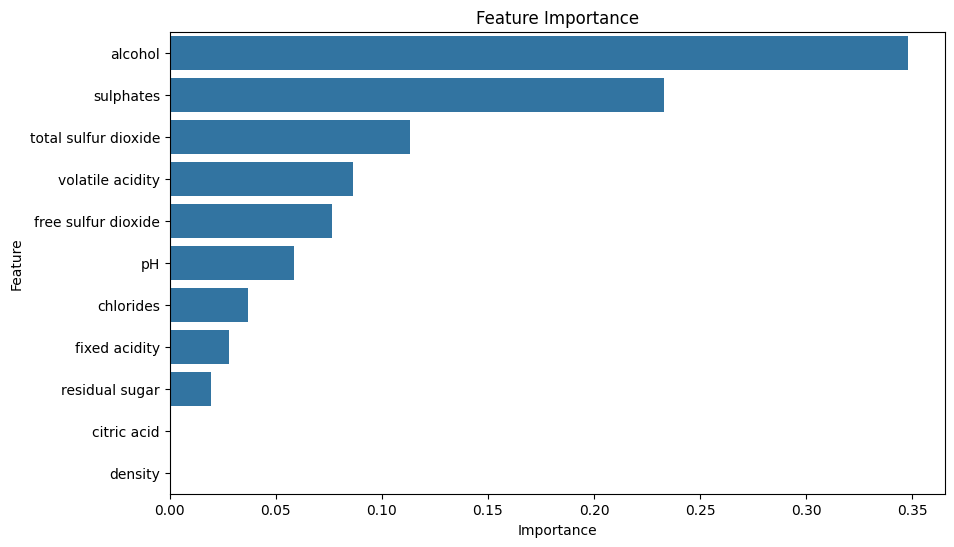

In [36]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance
)

plt.title("Feature Importance")
plt.show()